*Elena Cascone*

*Antonio Sirignano*

# Fase 2 — EDA

**Punto di partenza:** `vigneto_clean_hourly.csv`, il dataset già pulito .

**Obiettivo di questo notebook:** preparare il dataset alla fase di modeling.

## 0. Setup e caricamento

In [1]:
import pandas as pd
import numpy as np


pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

df = pd.read_csv("/Users/elecas/Documents/TIROCINIO/vigneto_clean_hourly.csv")
print("Righe:", len(df), " Colonne:", df.shape[1])
display(df)

Righe: 55787  Colonne: 41


,station_id,ts,irrigated,water_potential_last,direct_reading_last,temp_resistance_last,wind_dir_of_hi,solar_rad_hi,deg_days_heat,hum_out,solar_rad_avg,solar_energy,wind_dir_of_prevail,rainfall_mm,night_cloud_cover,deg_days_cool,emc,rain_rate_hi_mm,salinity_last_1,moist_soil_last_1,wind_chill_c,thw_index_c,temp_out_c,temp_out_lo_c,wet_bulb_c,temp_out_hi_c,dew_point_out_c,heat_index_out_c,thsw_index_c,temp_last_1_c,wind_speed_avg_kmh,wind_speed_hi_kmh,wind_run_kmh,bar_hpa,bar_alt_hpa,abs_press_hpa,pressure_last_hpa,et_mm,air_density_kgm3,watermark_available,bar_trend_cat
0,90411,2023-04-13 14:00:00,0,NaN,NaN,NaN,9.0,763.0,0.025000,60.0,549.0,47.237995,10.0,0.0,0.000000,0.000000,11.062000,0.0,NaN,NaN,15.995689,15.406800,18.000000,17.555556,12.590258,18.277778,10.115537,17.411111,18.888889,NaN,19.31208,41.84284,19.31208,1000.983020,1000.983020,954.882501,1000.983020,0.3810,1.128340,False,in lenta discesa
1,90411,2023-04-13 15:00:00,0,NaN,NaN,NaN,10.0,654.0,0.066667,65.0,503.0,43.279987,10.0,0.0,0.000000,0.000000,11.982000,0.0,0.870500,34.150000,15.087126,14.664904,17.444444,16.666667,12.922098,18.166667,10.791963,17.022224,17.777778,14.650000,20.92142,43.45218,20.92142,1000.441198,1000.441198,954.360930,1000.441198,0.3556,1.129188,False,in lenta discesa
2,90411,2023-04-13 16:00:00,0,NaN,NaN,NaN,11.0,397.0,0.225000,76.0,132.0,11.357770,10.0,0.0,0.000000,0.000000,14.966000,0.0,0.877500,34.450000,12.941297,12.679074,15.333333,14.777778,12.580651,16.777778,11.124361,15.071111,13.333333,14.100000,19.31208,51.49888,19.31208,1001.016884,1001.016884,954.915045,1001.016884,0.1270,1.137774,False,in lenta discesa
3,90411,2023-04-13 17:00:00,0,NaN,NaN,NaN,10.0,81.0,0.312500,83.0,44.0,3.785923,10.0,0.0,0.000000,0.000000,17.400000,0.0,0.882000,34.550000,12.627557,12.510891,14.166667,13.777778,12.347222,14.777778,11.319917,14.050000,11.111111,13.900000,14.48406,40.23350,14.48406,1001.186204,1001.186204,955.078065,1001.186204,0.0508,1.142383,False,stabile
4,90411,2023-04-13 18:00:00,0,NaN,NaN,NaN,11.0,14.0,0.404167,77.0,4.0,0.344175,10.0,0.0,0.000000,0.000000,15.444000,0.0,0.881500,34.600000,11.186283,10.919617,12.944444,12.222222,10.492833,13.777778,9.006102,12.677778,9.444444,13.750000,14.48406,33.79614,14.48406,1002.642351,1002.642351,956.479692,1002.642351,0.0254,1.151305,False,in rapida salita
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55782,90411,2026-07-28 02:00:00,1,-0.69,-0.32,1258.62,NaN,0.0,0.000000,93.0,0.0,0.000000,NaN,0.0,0.719156,0.233333,20.973999,0.0,0.665222,22.511111,21.444444,22.777778,21.444444,21.222222,20.640000,21.611111,20.264842,22.777778,21.666667,25.955556,0.00000,0.00000,0.00000,1022.926827,1022.926827,969.812214,1022.926827,0.0000,1.119376,True,stabile
55783,90411,2026-07-28 03:00:00,1,-0.63,-0.33,1257.51,NaN,0.0,0.000000,93.0,0.0,0.000000,NaN,0.0,0.719156,0.200000,20.950000,0.0,0.664556,22.455556,21.000000,22.326667,21.000000,20.611111,20.200000,21.166667,19.824342,22.326667,20.555556,25.922222,0.00000,0.00000,0.00000,1022.994555,1022.994555,969.877064,1022.994555,0.0000,1.121899,True,stabile
55784,90411,2026-07-28 04:00:00,1,-0.58,-0.34,1256.72,NaN,7.0,0.000000,94.0,0.0,0.000000,NaN,0.0,0.719156,0.170833,21.350000,0.0,0.664111,22.466667,20.611111,21.960000,20.611111,20.388889,19.940000,20.833333,19.611128,21.960000,20.555556,25.900000,0.00000,0.00000,0.00000,1023.705697,1023.705697,970.558101,1023.705697,0.0000,1.124552,True,in lenta salita
55785,90411,2026-07-28 05:00:00,1,-0.50,-0.36,1258.46,4.0,81.0,0.000000,94.0,43.0,3.699880,10.0,0.0,0.757336,0.170833,21.350000,0.0,0.666000,22.511111,20.611111,21.960000,20.611111,20.277778,19.940000,21.222222,19.611128,21.960000,22.777778,25.877778,0.00000,6.43736,0.00000,1023.976608,1023.976608,970.817634,1023.976608,0.0254,1.124860,True,in lenta salita


In [2]:


exclude = ["station_id", "irrigated", "wind_dir_of_hi", "wind_dir_of_prevail"]
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in exclude]

# describe() da' i quantili (gia' visti nei boxplot), ma non la FORMA della
# distribuzione: aggiungo skewness (asimmetria) e kurtosi (code pesanti/leggere
# rispetto a una normale), che servono a decidere se una variabile va trasformata
# (es. log) prima di un modello lineare
stats = df[num_cols].describe().T
stats["skew"] = df[num_cols].skew()
stats["kurtosis"] = df[num_cols].kurtosis()
print(stats[["mean", "std", "skew", "kurtosis"]].round(2))

                         mean     std   skew  kurtosis
water_potential_last    -4.54    2.81   0.01     -1.46
direct_reading_last     -0.13    0.37   0.97      0.56
temp_resistance_last  1279.41   34.19   0.03     -1.11
solar_rad_hi           227.48  317.97   1.21      0.13
deg_days_heat            0.32    0.35   0.68     -0.75
hum_out                 75.16   14.74  -0.76     -0.18
solar_rad_avg          160.27  246.96   1.56      1.30
solar_energy            13.79   21.25   1.56      1.30
rainfall_mm              0.10    0.74  20.26    646.60
night_cloud_cover        0.46    0.29  -0.59     -1.21
deg_days_cool            0.17    0.29   1.86      2.64
emc                     15.48    4.11  -0.27     -1.07
rain_rate_hi_mm          0.61    6.32  21.10    579.07
salinity_last_1          0.91    0.14  -0.47      0.48
moist_soil_last_1       31.49    5.39  -0.23     -1.55
wind_chill_c            16.03    7.61   0.36     -0.61
thw_index_c             16.23    8.04   0.48     -0.38
temp_out_c

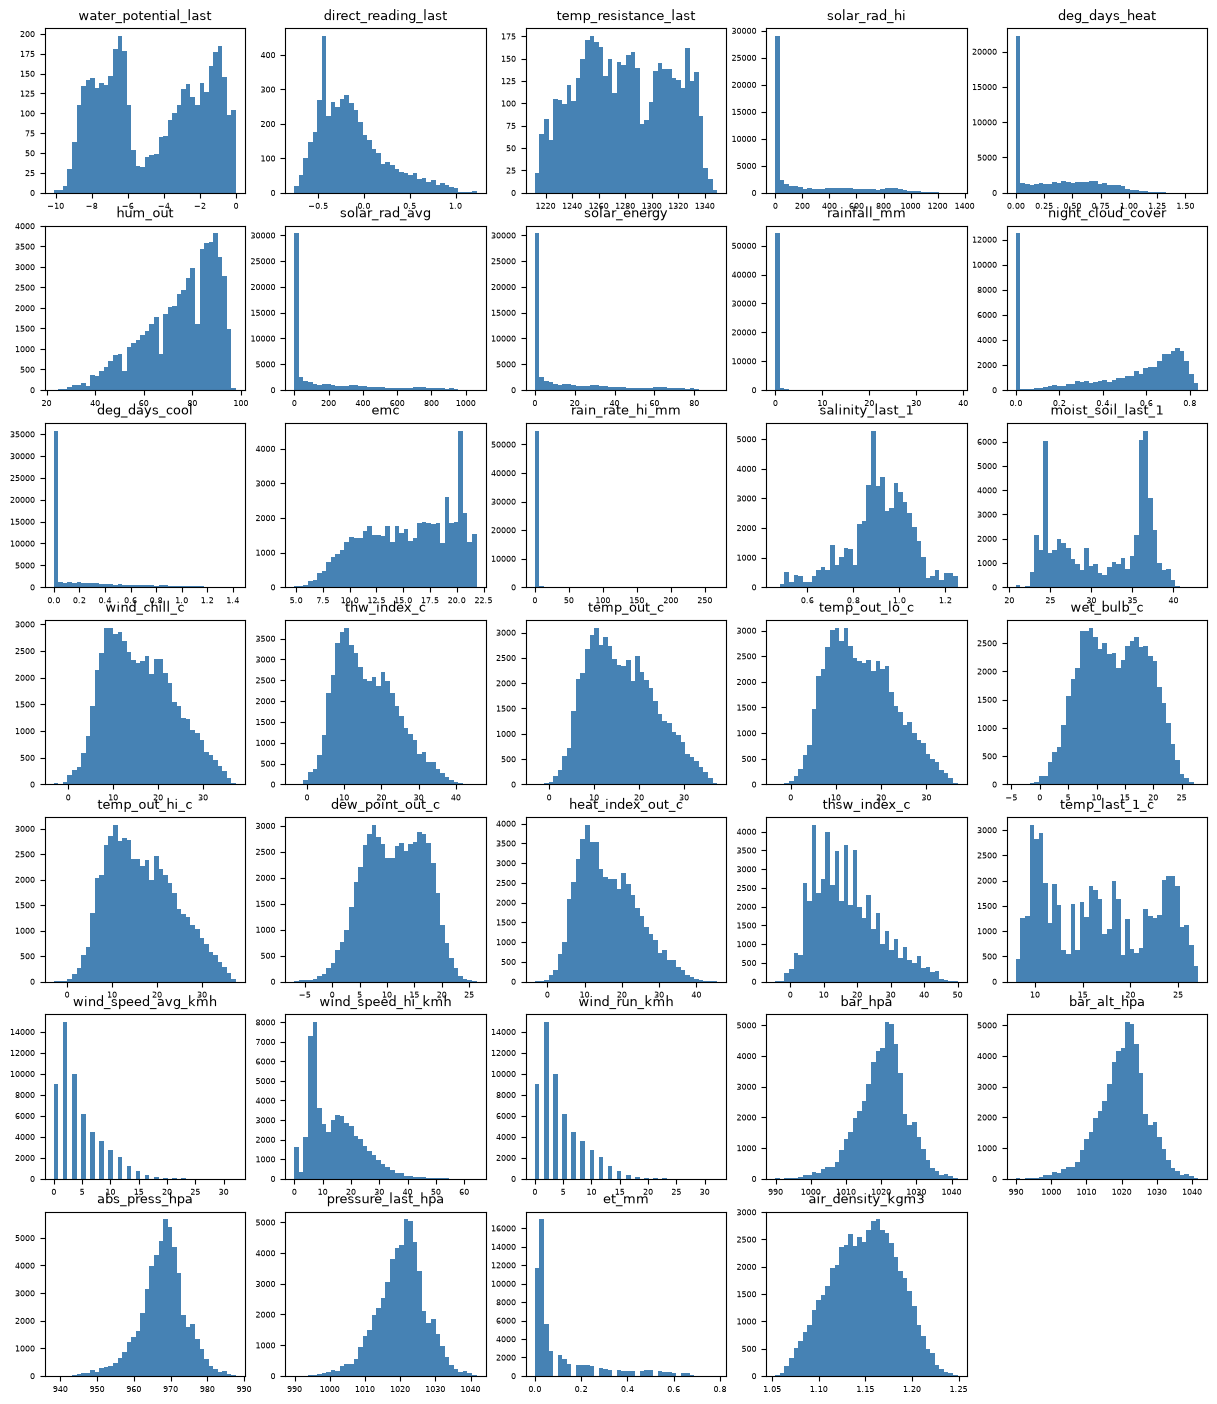

In [3]:
import matplotlib.pyplot as plt

exclude = ["station_id", "irrigated", "wind_dir_of_hi", "wind_dir_of_prevail"]
num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in exclude]

n = len(num_cols)
ncols = 5
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3, nrows * 2.5))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    ax.hist(df[col].dropna(), bins=40, color="steelblue", edgecolor="none")
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis="both", labelsize=6)

for j in range(i + 1, len(axes)):
    axes[j].axis("off")

plt.show()


non si iesce a capire molto quindi separo la rappresentazione tra irrigato e non irrigato:

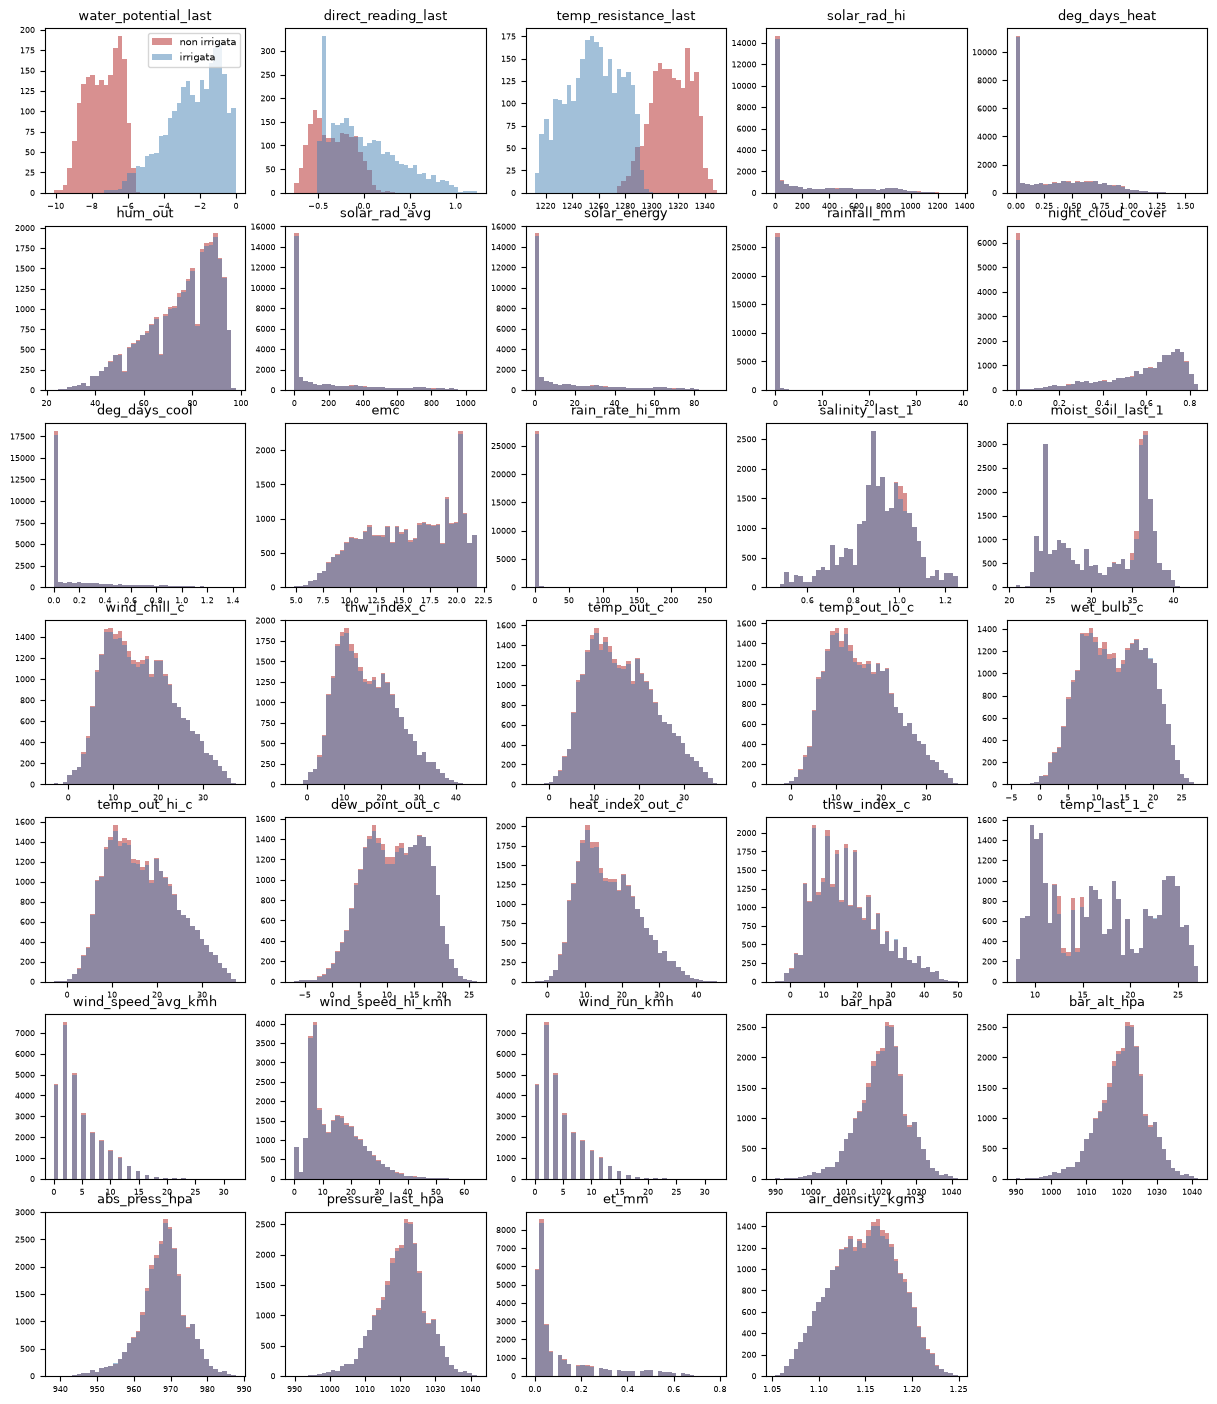

In [4]:
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 3, nrows * 2.5))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    ax = axes[i]
    # stesso bin edges per le due zone, altrimenti il confronto visivo e' fuorviante
    bins = np.histogram_bin_edges(df[col].dropna(), bins=40)
    ax.hist(df.loc[df["irrigated"] == 0, col].dropna(), bins=bins,
            alpha=0.5, label="non irrigata", color="firebrick")
    ax.hist(df.loc[df["irrigated"] == 1, col].dropna(), bins=bins,
            alpha=0.5, label="irrigata", color="steelblue")
    ax.set_title(col, fontsize=9)
    ax.tick_params(axis="both", labelsize=6)

axes[0].legend(fontsize=7)
for j in range(i + 1, len(axes)):
    axes[j].axis("off")
plt.show()

le uniche tre variabili davvero zona-specifiche sono le tre della sonda Watermark (water_potential, direct_reading e temp_resistance).

In [5]:
target_cols = ["water_potential_last", "direct_reading_last", "temp_resistance_last"]
print(df[target_cols].corr())

                      water_potential_last  direct_reading_last  temp_resistance_last
water_potential_last              1.000000             0.114128             -0.843841
direct_reading_last               0.114128             1.000000             -0.195209
temp_resistance_last             -0.843841            -0.195209              1.000000


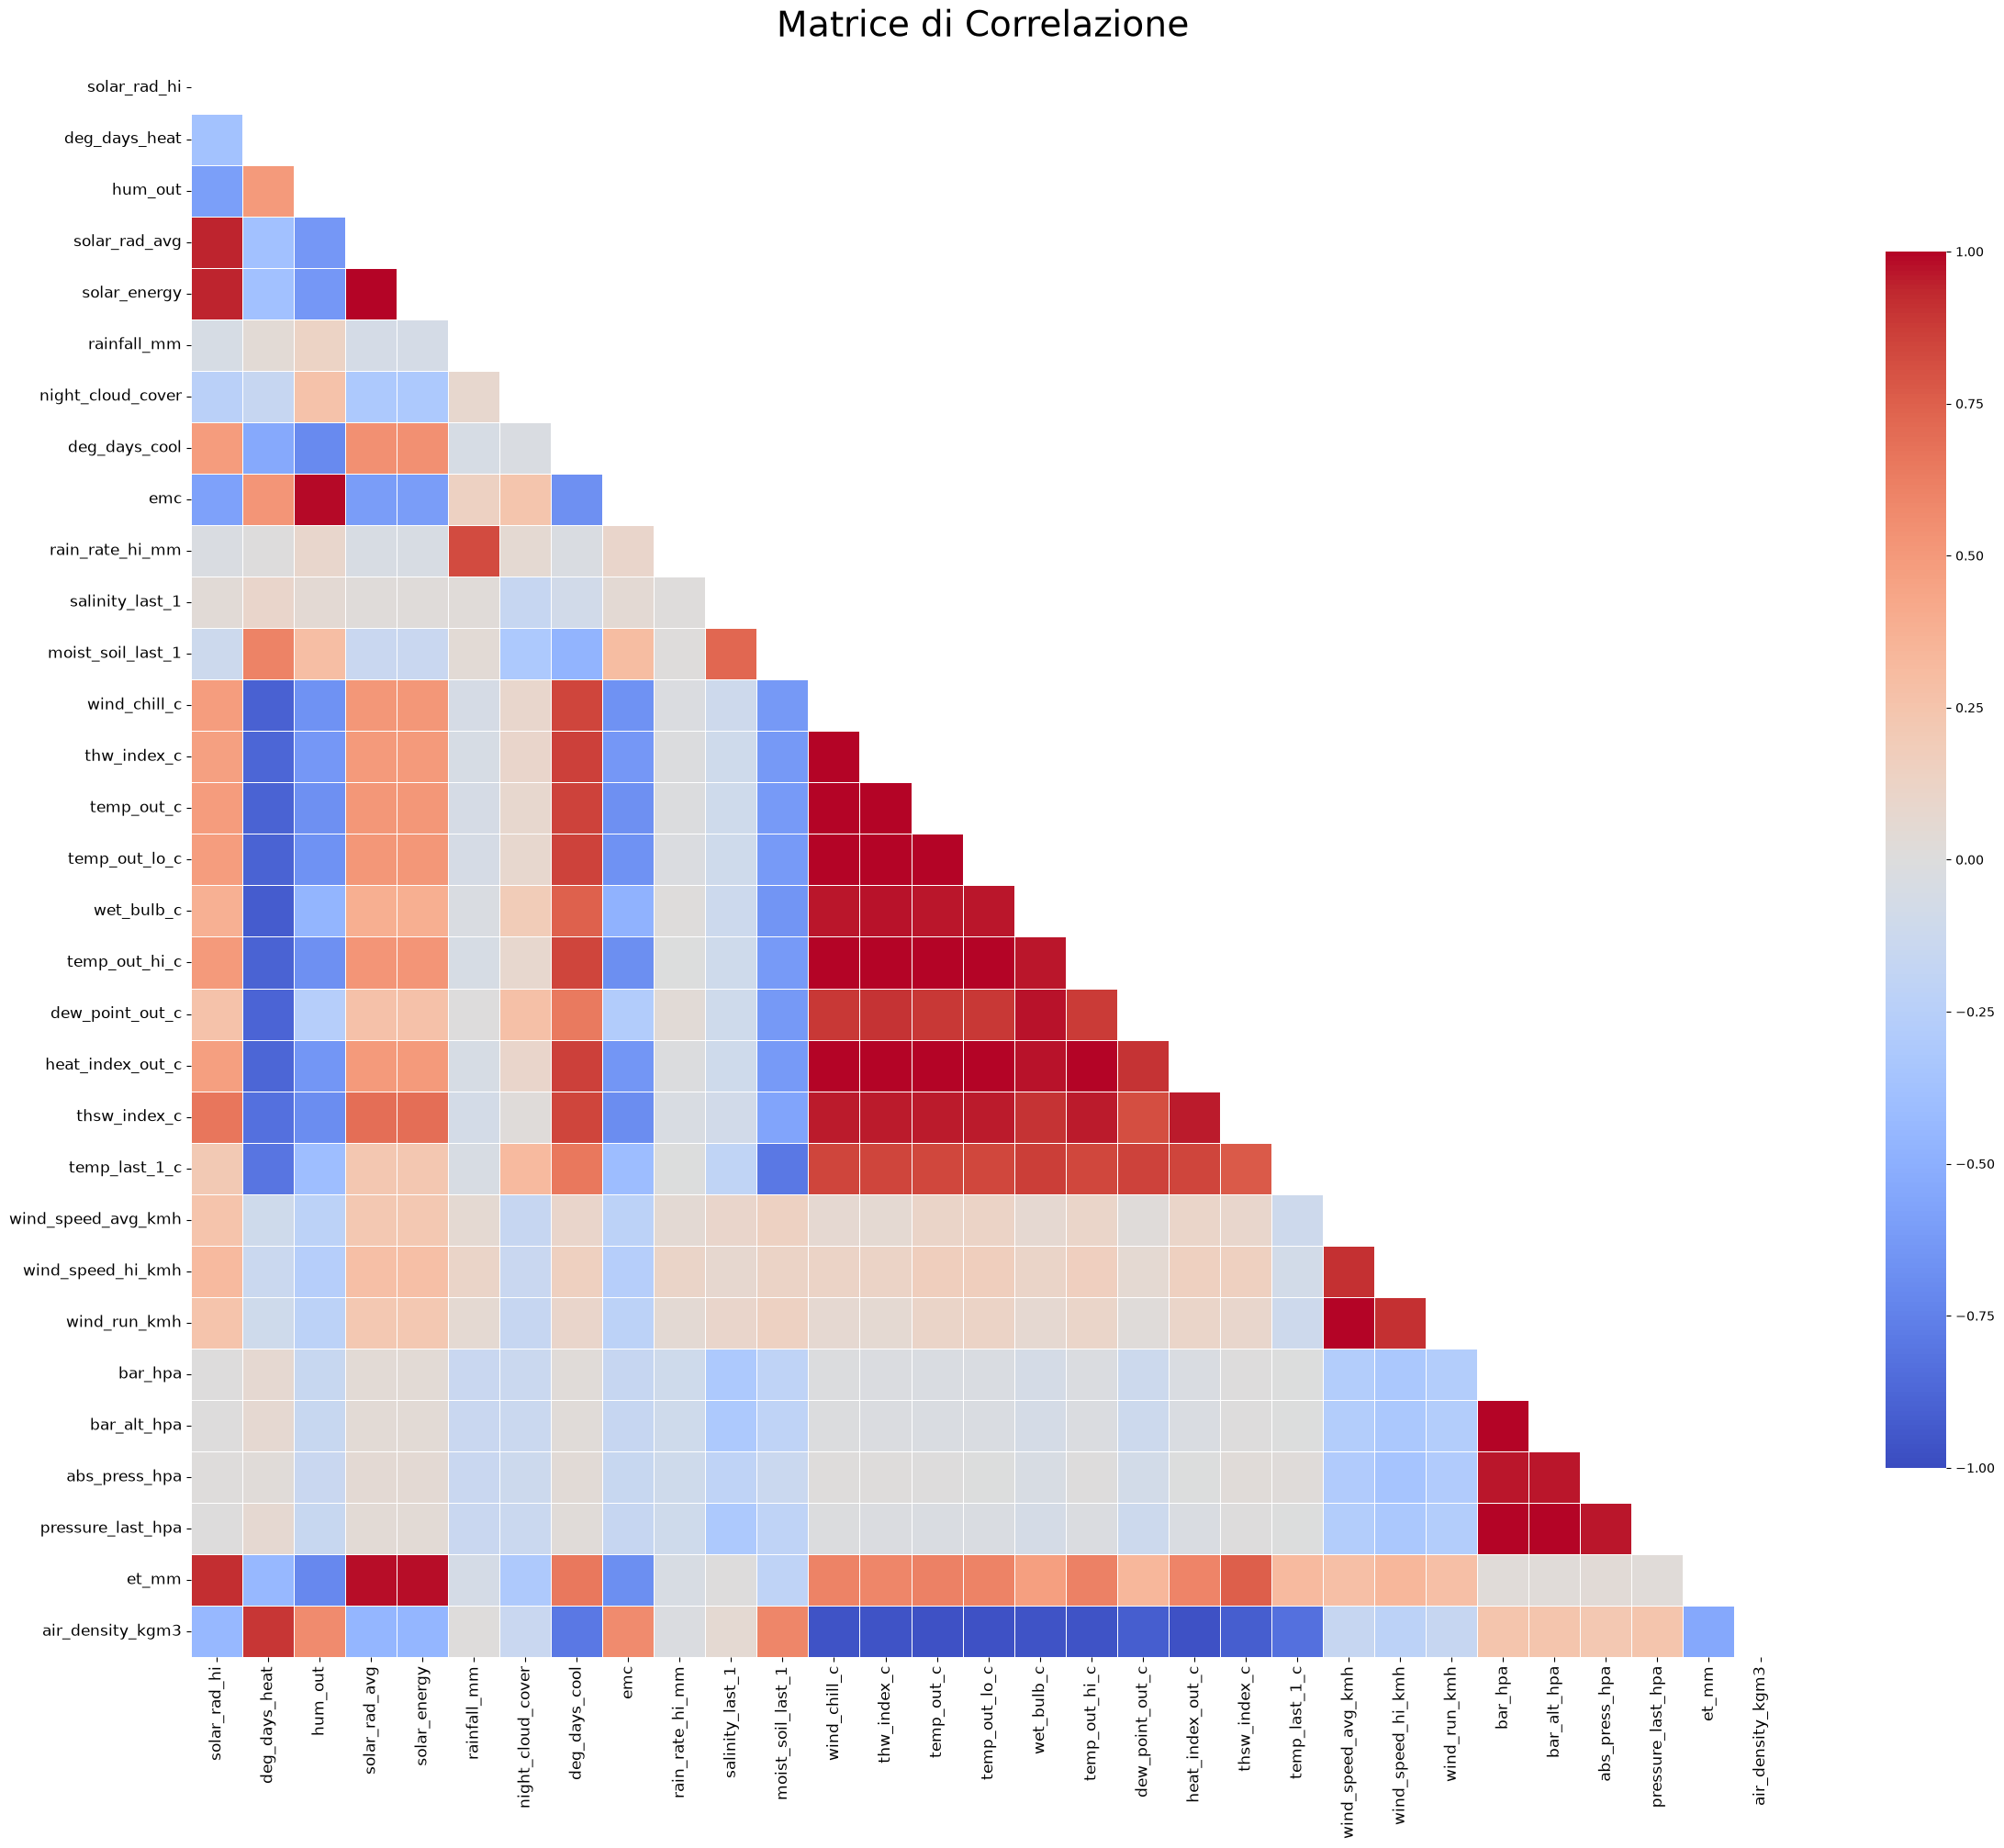

In [6]:

import seaborn as sns

# 1. la matrice di correlazione su tutte le variabili numeriche candidate
#    (escludo id/target/flag/circolari)
exclude = [
    "station_id", "ts", "irrigated",
    "water_potential_last", "direct_reading_last", "temp_resistance_last",
    "watermark_available",
    "wind_dir_of_hi", "wind_dir_of_prevail",
]
candidate_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in exclude]
corr_matrix = df[candidate_cols].corr()

# --- Matrice di Correlazione ---
plt.figure(figsize=(24, 20))

# Maschera per la metà superiore della matrice 
mask = pd.DataFrame(False, index=corr_matrix.index, columns=corr_matrix.columns)
import numpy as np
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', vmin=-1, vmax=1, center=0,
            square=True, linewidths=.5, cbar_kws={"shrink": .75})
plt.title("Matrice di Correlazione ", fontsize=28, pad=20)
plt.xticks(rotation=90, fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()


Leggendo andando da sinistra a destra:

1. 'solar_rad_hi', 'solar_rad_avg', 'solar_energy': un piccolo blocco rosso scurissimo tra loro tre — sono quasi la stessa informazione (radiazione solare misurata in tre modi diversi) e quindi costituiscono il gruppo della Radiazione solare.

2. 'hum_out' ↔ 'emc': una singola cella rosso scurissimo tra le due — praticamente identiche.

3. Il grande blocco rosso scuro al centro ('wind_chill_c', 'thw_index_c', 'temp_out_c', 'temp_out_lo_c', 'wet_bulb_c', 'temp_out_hi_c', 'dew_point_out_c', 'heat_index_out_c', 'thsw_index_c'): è il blocco più grande e più uniformemente rosso scuro di tutta la matrice — tutte queste variabili sono varianti/indici derivati dalla stessa temperatura, quindi si muovono quasi all'unisono.

4. 'temp_last_1_c', subito dopo quel blocco: il colore è arancione, non rosso scuro come le celle vicine. È correlata con il gruppo temperatura, ma più debolmente. Questo è il primo segnale visivo che questa variabile, pur essendo "temperatura", non è così ridondante con le altre da meritare di essere buttata via.

5. 'wind_speed_avg_kmh', 'wind_speed_hi_kmh', 'wind_run_kmh': altro blocco rosso scuro compatto, isolato dal resto — il gruppo vento.

6. 'bar_hpa', 'bar_alt_hpa', 'abs_press_hpa', 'pressure_last_hpa': blocco rosso scuro isolato in basso — il gruppo pressione.

7. 'et_mm': è rosso scurissimo con il gruppo solare, ma solo arancione tenue con tutto il blocco temperatura. Quindi et_mm appartiene al gruppo radiazione solare, non al gruppo temperatura.

8. 'air_density_kgm3': qui il colore è blu scuro con tutto il blocco temperatura — è una correlazione fortemente negativa, non positiva: l'aria più calda è meno densa. Stesso livello di ridondanza del punto 3, solo con segno opposto — appartiene comunque a quel gruppo.

9. Il resto ('rainfall_mm', 'rain_rate_hi_mm', 'salinity_last_1', 'night_cloud_cover', 'deg_days_cool', 'moist_soil_last_1'): quasi tutte le celle sulle loro righe/colonne sono grigie o beige tenue — nessun legame forte con nient'altro nella matrice. Sono le variabili "isolate".

10. 'deg_days_heat' è correlata positivamente con 'air_density_kgm3' (rosso scuro), ma negativamente con tutto il blocco temperatura (blu scuro).




Adesso facciamo un clustering gerarchico per leggere più elegantemente queste correlazioni:

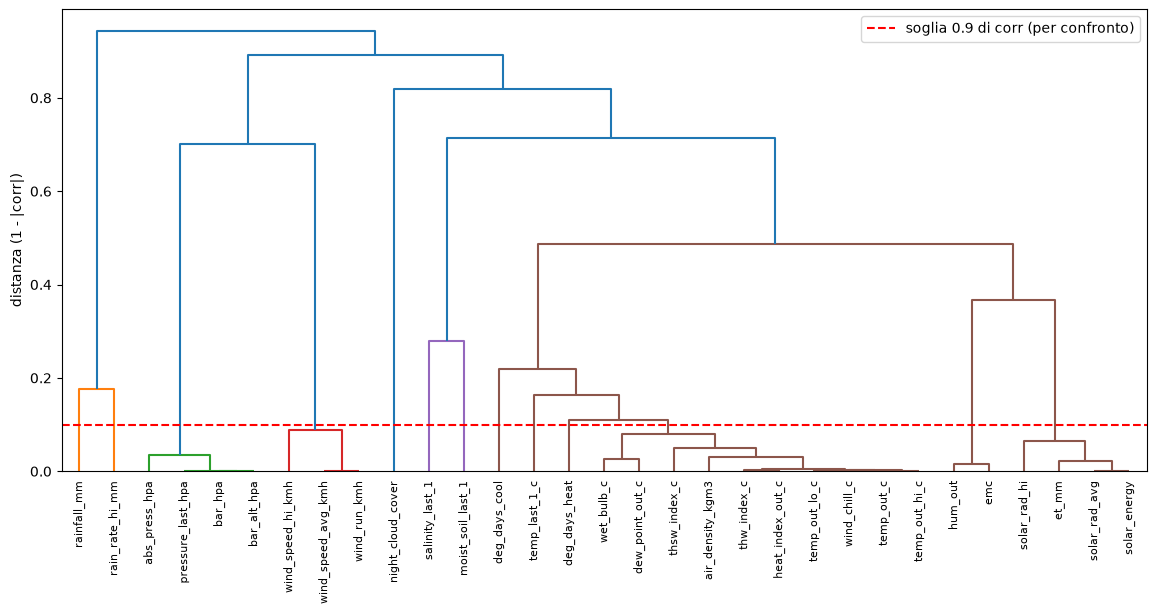

In [7]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

corr_matrix = df[candidate_cols].corr()

# distanza = 1 - |correlazione|: 0 = identiche, 1 = incorrelate
dist_matrix = 1 - corr_matrix.abs()


condensed = squareform(dist_matrix.values, checks=False)

# 'average linkage': la distanza tra due gruppi e' la MEDIA delle distanze tra
# tutte le coppie nei due gruppi -- scelta standard, meno sensibile agli
# outlier del 'single linkage' e meno aggressiva del 'complete linkage'
Z = linkage(condensed, method="average")

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, labels=candidate_cols, leaf_rotation=90, ax=ax)
ax.axhline(y=1 - 0.9, color="red", linestyle="--", label="soglia 0.9 di corr (per confronto)")
ax.set_ylabel("distanza (1 - |corr|)")
ax.legend()
plt.show()

Qui confermiamo quanto visto con la matrice sopra, quindi distinguiamo diversi gruppi (da sx a dx):

1. Gruppo pressione: in verde;

2. Gruppo vento: in rosso;

3. Gruppo temperatura: marrone;

4. Gruppo umidità: sempre marrone (hum_out e emc);

5. Gruppo radiazione solare/ET : in marrone, l'ultimo gruppo.

I dati del vento, sono circolari? I dati circolari sono misure dove il valore più alto e il valore più basso della scala sono in realtà vicini fisicamente, non lontani — perché la scala si "richiude su se stessa" come un cerchio, invece di essere una retta con un inizio e una fine.

**Perchè questa intuizione?**

Quando abbiamo controllato i range fisici di tutte le variabili, ci aspettavamo che wind_dir_of_hi e wind_dir_of_prevail (nome che suggerisce "direzione del vento") fossero espresse in gradi bussola, cioè un continuo da 0° a 360° (0=Nord, 90=Est, 180=Sud, 270=Ovest, e tutti i valori intermedi) — è così che quasi ogni centralina meteo riporta la direzione del vento. 

Guardando i valori reali nel dataset, il massimo era 15, non 360.

0-15 significa esattamente 16 valori interi possibili (0,1,2...15). Sedici non è un numero a caso in meteorologia — è il numero standard delle direzioni della "rosa dei venti": N, NNE, NE, ENE, E, ESE, SE, SSE, S, SSW, SW, WSW, W, WNW, NW, NNW.

Per questo motivo la correlazione di Pearson usata per questi tipi di dati non funziona e quindi si utilizza un altro metodo più consono per questa tipologia:

In [8]:
# converto i codici 0-15 (rosa dei venti a 16 punte) in angoli (radianti)
theta_hi = df["wind_dir_of_hi"].dropna() * (2 * np.pi / 16)
theta_prevail = df["wind_dir_of_prevail"].dropna() * (2 * np.pi / 16)

# allineo gli indici (stesse righe non-null per entrambe)
common = df[["wind_dir_of_hi", "wind_dir_of_prevail"]].dropna()
a = common["wind_dir_of_hi"] * (2 * np.pi / 16)
b = common["wind_dir_of_prevail"] * (2 * np.pi / 16)

# correlazione circolare di Jammalamadaka-SenGupta: stessa idea del coefficiente
# di Pearson, ma usando seno degli scarti dalla MEDIA CIRCOLARE invece della
# media aritmetica (che per angoli non ha senso: la media tra 359° e 1° non e' 180°)
def circular_mean(angles):
    return np.arctan2(np.sin(angles).sum(), np.cos(angles).sum())

mean_a, mean_b = circular_mean(a), circular_mean(b)
num = np.sum(np.sin(a - mean_a) * np.sin(b - mean_b))
den = np.sqrt(np.sum(np.sin(a - mean_a)**2) * np.sum(np.sin(b - mean_b)**2))
r_circ = num / den
print(f"correlazione circolare: {r_circ:.3f}  (n={len(common)})")

correlazione circolare: 0.603  (n=54166)


Moderata, ben lontana da qualunque soglia di ridondanza. Le due variabili portano informazione diversa (direzione della raffica più forte vs direzione prevalente nell'ora), le tengo entrambe.

Adesso, quali variabili tenere e quali eliminare? Dentro ogni gruppo di variabili, tengo quella più correlata col target : 'water_potential_last':

In [9]:
raw=pd.read_csv("/Users/elecas/Documents/TIROCINIO/history_last_4_years_irr_noirr_28_07.csv")

raw["ts"] = pd.to_datetime(raw["ts"])
df["ts"] = pd.to_datetime(df["ts"])

raw_weather = raw.drop(columns=["water_potential_last", "direct_reading_last", "temp_resistance_last"], errors="ignore")

check = df[["ts", "irrigated", "water_potential_last", "watermark_available"]].merge(
    raw_weather, on=["ts", "irrigated"], how="left"   
)
sub = check[check["watermark_available"]]

GRUPPI = {
    "temperatura": ["wind_chill", "thw_index", "temp_out", "temp_out_lo", "wet_bulb",
                     "temp_out_hi", "dew_point_out", "heat_index_out", "thsw_index", "air_density"],
    "radiazione/ET": ["solar_rad_hi", "solar_rad_avg", "solar_energy", "et"],
    "umidita": ["hum_out", "emc"],
    "pressione": ["bar", "bar_alt", "abs_press", "pressure_last"],
    "vento": ["wind_speed_avg", "wind_speed_hi", "wind_run"],
}

vincitori = {}
for nome, cols in GRUPPI.items():
    cols = [c for c in cols if c in sub.columns]
    corr = sub[cols + ["water_potential_last"]].corr()["water_potential_last"].drop("water_potential_last")
    corr_ord = corr.reindex(corr.abs().sort_values(ascending=False).index)
    vincitori[nome] = corr_ord.index[0]
    print(f"--- {nome} ---")
    print(corr_ord.round(3))
    print(f"-> tengo: {corr_ord.index[0]}\n")

--- temperatura ---
wind_chill       -0.311
temp_out         -0.310
temp_out_hi      -0.310
temp_out_lo      -0.309
thw_index        -0.300
heat_index_out   -0.299
thsw_index       -0.281
air_density       0.279
wet_bulb         -0.254
dew_point_out    -0.179
Name: water_potential_last, dtype: float64
-> tengo: wind_chill

--- radiazione/ET ---
et              -0.208
solar_rad_avg   -0.175
solar_energy    -0.175
solar_rad_hi    -0.166
Name: water_potential_last, dtype: float64
-> tengo: et

--- umidita ---
hum_out    0.268
emc        0.266
Name: water_potential_last, dtype: float64
-> tengo: hum_out

--- pressione ---
bar             -0.1
bar_alt         -0.1
abs_press       -0.1
pressure_last   -0.1
Name: water_potential_last, dtype: float64
-> tengo: bar

--- vento ---
wind_speed_hi    -0.131
wind_speed_avg   -0.091
wind_run         -0.091
Name: water_potential_last, dtype: float64
-> tengo: wind_speed_hi



|Gruppo|Esito|Decisione|
|---|---|---|
|Temperatura|	'wind_chill' -0,311 vs 'temp_out' -0,310 → distacco 0,001	|Pareggio → tengo 'temp_out_c'|
|Umidità|	'hum_out' 0,268 vs 'emc' 0,266 → distacco 0,002	|Pareggio → tengo 'hum_out'|
|Pressione|	tutte a -0,1 → distacco 0	|Pareggio totale → tengo 'bar' |
|Radiazione/ET|	'et' -0,208 | tengo 'et' |
|Vento|	'wind_speed_hi' -0,131 | tengo solo 'wind_speed_hi' |


In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance

feature_cols = [
    "wind_chill", "thw_index", "temp_out", "temp_out_lo", "wet_bulb", "temp_out_hi",
    "dew_point_out", "heat_index_out", "thsw_index", "air_density",
    "solar_rad_hi", "solar_rad_avg", "solar_energy", "et",
    "hum_out", "emc",
    "bar", "bar_alt", "abs_press", "pressure_last",
    "wind_speed_avg", "wind_speed_hi", "wind_run",
    "moist_soil_last_1", "salinity_last_1", "temp_last_1",
    "deg_days_cool", "deg_days_heat", "night_cloud_cover",
    "rain_rate_hi_mm", "rainfall_mm",
]  

def fit_and_explain(data_zona, nome_zona):
    data = data_zona[feature_cols + ["ts", "water_potential_last"]].dropna().sort_values("ts")
    split = int(len(data) * 0.8)
    train, test = data.iloc[:split], data.iloc[split:]
    X_train, y_train = train[feature_cols], train["water_potential_last"]
    X_test, y_test = test[feature_cols], test["water_potential_last"]

    rf = RandomForestRegressor(n_estimators=300, max_depth=8, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    r2 = rf.score(X_test, y_test)

    perm = permutation_importance(rf, X_test, y_test, n_repeats=20, random_state=42, n_jobs=-1)
    importanze = pd.Series(perm.importances_mean, index=feature_cols).sort_values(ascending=False)

    print(f"=== {nome_zona} (n={len(data)}, train {train['ts'].min().date()}->{train['ts'].max().date()}, R2 test={r2:.3f}) ===")
    print(importanze.head(10).round(4))
    print()
    return importanze

imp_0 = fit_and_explain(sub[sub["irrigated"] == 0], "NON IRRIGATA")
imp_1 = fit_and_explain(sub[sub["irrigated"] == 1], "IRRIGATA")

=== NON IRRIGATA (n=1838, train 2026-05-12->2026-07-12, R2 test=0.945) ===
thsw_index           0.1897
et                   0.1017
temp_out_hi          0.0398
night_cloud_cover    0.0326
solar_rad_hi         0.0323
temp_out_lo          0.0131
emc                  0.0129
solar_rad_avg        0.0123
solar_energy         0.0117
wind_chill           0.0045
dtype: float64

=== IRRIGATA (n=2359, train 2026-03-09->2026-07-08, R2 test=-0.183) ===
night_cloud_cover    0.0149
solar_rad_hi         0.0075
salinity_last_1      0.0043
solar_rad_avg        0.0038
wet_bulb             0.0037
solar_energy         0.0006
rainfall_mm          0.0000
rain_rate_hi_mm     -0.0000
moist_soil_last_1   -0.0001
deg_days_heat       -0.0001
dtype: float64



**Zona non irrigata**: R² test = 0,945, con importanza distribuita su diverse variabili meteo sensate — thsw_index, et , temp_out_hi , night_cloud_cover, il gruppo radiazione solare, emc. Il modello impara davvero dal meteo.

**Zona irrigata**: R² test = -0,174. Negativo — significa che il modello è peggiore che prevedere semplicemente la media costante. Tutte le importanze sono vicine a zero o negative (rumore). In pratica: nella zona irrigata, il meteo da solo non spiega quasi nulla delle variazioni del potenziale idrico.

Questo non è un fallimento del modello, è un risultato ottimo, ci fa rendere conto che quello che manca per davvero è quando e quanto è stata data l'acqua — esattamente i dati di flusso Solem che non abbiamo ancora integrato. Il potenziale idrico lì si muove sugli eventi di irrigazione, non sul meteo del giorno.



Alla luce di ciò ricalcoliamo la correlazione escludendo i dati della zona irrigata, perchè l'influenza di quei dati nasconde quanto il meteo conti davvero nell'analisi:

In [11]:
raw_weather = raw.drop(columns=["water_potential_last", "direct_reading_last", "temp_resistance_last"], errors="ignore")
check = df[["ts", "irrigated", "water_potential_last", "watermark_available"]].merge(
    raw_weather, on=["ts", "irrigated"], how="left"
)

# il filtro nuovo rispetto a prima: solo zona non irrigata (irrigated == 0),
# dove la relazione meteo-target non e' annacquata dall'effetto irrigazione
sub = check[(check["watermark_available"]) & (check["irrigated"] == 0)]

GRUPPI = {
    "temperatura": ["wind_chill", "thw_index", "temp_out", "temp_out_lo", "wet_bulb", "temp_out_hi",
                     "dew_point_out", "heat_index_out", "thsw_index", "air_density"],
    "radiazione/ET": ["solar_rad_hi", "solar_rad_avg", "solar_energy", "et"],
    "umidita": ["hum_out", "emc"],
    "pressione": ["bar", "bar_alt", "abs_press", "pressure_last"],
    "vento": ["wind_speed_avg", "wind_speed_hi", "wind_run"],
}

for nome, cols in GRUPPI.items():
    cols = [c for c in cols if c in sub.columns]
    corr = sub[cols + ["water_potential_last"]].corr()["water_potential_last"].drop("water_potential_last")
    corr_ord = corr.reindex(corr.abs().sort_values(ascending=False).index)
    print(f"--- {nome} ---")
    print(corr_ord.round(3))
    print(f"-> tengo: {corr_ord.index[0]}\n")

--- temperatura ---
thsw_index       -0.858
temp_out_hi      -0.803
temp_out         -0.797
wind_chill       -0.795
temp_out_lo      -0.786
heat_index_out   -0.768
thw_index        -0.766
air_density       0.733
wet_bulb         -0.613
dew_point_out    -0.377
Name: water_potential_last, dtype: float64
-> tengo: thsw_index

--- radiazione/ET ---
et              -0.809
solar_rad_hi    -0.784
solar_rad_avg   -0.777
solar_energy    -0.777
Name: water_potential_last, dtype: float64
-> tengo: et

--- umidita ---
hum_out    0.722
emc        0.719
Name: water_potential_last, dtype: float64
-> tengo: hum_out

--- pressione ---
bar             -0.123
bar_alt         -0.123
abs_press       -0.123
pressure_last   -0.123
Name: water_potential_last, dtype: float64
-> tengo: bar

--- vento ---
wind_speed_hi    -0.492
wind_speed_avg   -0.412
wind_run         -0.412
Name: water_potential_last, dtype: float64
-> tengo: wind_speed_hi



Sostituzione di 'temp_out_c' con 'thsw_index_c' nel dataset finale:

In [12]:
# --- 1. drop delle variabili ridondanti per multicollinearita' (dal file a 41 colonne) ---
drop_cols_multicollinearita = [
    # gruppo temperatura (rappresentante scelto poi sostituito al punto 3)
    "wind_chill_c", "thw_index_c", "temp_out_hi_c", "temp_out_lo_c",
    "wet_bulb_c", "dew_point_out_c", "heat_index_out_c", "thsw_index_c",
    "air_density_kgm3",
    # gruppo radiazione/ET
    "solar_rad_hi", "solar_rad_avg", "solar_energy",
    # gruppo umidita'
    "emc",
    # gruppo pressione
    "bar_alt_hpa", "abs_press_hpa", "pressure_last_hpa",
    # gruppo vento (parte 1: il duplicato tautologico)
    "wind_run_kmh",
    # target ridondante col target principale
    "temp_resistance_last",
    # variabile costante, zero informazione
    "station_id",
]
df = df.drop(columns=drop_cols_multicollinearita)
print("dopo il primo drop:", df.shape[1])  

# --- 2. correzione sul gruppo vento: la raffica batte la media come predittore ---
df = df.drop(columns=["wind_speed_avg_kmh"])
print("dopo la correzione vento:", df.shape[1])  

# --- 3. correzione sul gruppo temperatura: rifatta la selezione sulla zona non
#     irrigata, thsw_index batte temp_out_c -> si sostituisce, non si somma ---
raw["thsw_index_c"] = (raw["thsw_index"] - 32) * 5 / 9
df = df.merge(raw[["ts", "irrigated", "thsw_index_c"]], on=["ts", "irrigated"], how="left")
df = df.drop(columns=["temp_out_c"])
print("dopo la correzione temperatura:", df.shape[1])  

print(sorted(df.columns.tolist()))

dopo il primo drop: 22
dopo la correzione vento: 21
dopo la correzione temperatura: 21
['bar_hpa', 'bar_trend_cat', 'deg_days_cool', 'deg_days_heat', 'direct_reading_last', 'et_mm', 'hum_out', 'irrigated', 'moist_soil_last_1', 'night_cloud_cover', 'rain_rate_hi_mm', 'rainfall_mm', 'salinity_last_1', 'temp_last_1_c', 'thsw_index_c', 'ts', 'water_potential_last', 'watermark_available', 'wind_dir_of_hi', 'wind_dir_of_prevail', 'wind_speed_hi_kmh']


ok adesso dopo aver aggiustato le colonne del dataset passiamo ad analizzare i missing values:

In [13]:
df.isna().sum().sort_values(ascending=False)

water_potential_last    51590
direct_reading_last     51197
wind_dir_of_hi           1621
wind_dir_of_prevail      1621
salinity_last_1             8
temp_last_1_c               8
moist_soil_last_1           8
thsw_index_c                5
et_mm                       3
bar_hpa                     3
wind_speed_hi_kmh           3
deg_days_cool               3
rain_rate_hi_mm             3
night_cloud_cover           3
rainfall_mm                 3
hum_out                     3
deg_days_heat               3
irrigated                   0
watermark_available         0
bar_trend_cat               0
ts                          0
dtype: int64

Prima di decidere come trattarli, li raggruppiamo per causa probabile perchè non sono tutti dello stesso tipo e quindi vanno trattati in modo diverso:

- **Gruppo 1 — enormi** ('water_potential_last' 51.590, 'direct_reading_last' 51.197): non sono un problema da risolvere perchè questi dati fanno riferimento a una sonda non installata per la maggior parte dei 4 anni, (documentato dal flag 'watermark_available'). Nessuna imputazione ha senso qui (perchè inventeremmo un potenziale idrico per un periodo in cui il sensore non esisteva).

- **Gruppo 2 — medi** ('wind_dir_of_hi'/'wind_dir_of_prevail', 1.621 = 2,9%): qui bisogna verificare se i missing values corrispondono con raffiche di vento deboli (assenza di vento o vento calmo)

- **Gruppo 3 — piccolissimi** (3-8 righe): troppo pochi per essere sistematici, probabile downtime breve della centralina. Controllo se sono le stesse righe per più colonne insieme (un unico blackout) o sparse a caso.

In [14]:
# ipotesi gruppo 2: i missing di wind_dir coincidono con raffiche deboli/assenti?
missing_dir = df[df["wind_dir_of_hi"].isnull()]
print("wind_speed_hi_kmh quando wind_dir_of_hi è mancante:")
print(missing_dir["wind_speed_hi_kmh"].describe())
print()
print("wind_speed_hi_kmh quando wind_dir_of_hi è presente:")
print(df[df["wind_dir_of_hi"].notnull()]["wind_speed_hi_kmh"].describe())

wind_speed_hi_kmh quando wind_dir_of_hi è mancante:
count    1618.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: wind_speed_hi_kmh, dtype: float64

wind_speed_hi_kmh quando wind_dir_of_hi è presente:
count    54166.000000
mean        14.015335
std          8.962646
min          1.609340
25%          6.437360
50%         12.874720
75%         19.312080
max         64.373600
Name: wind_speed_hi_kmh, dtype: float64


L'ipotesi sul gruppo 2 è confermata, quando 'wind_dir_of_hi' è mancante, 'wind_speed_hi_kmh' è esattamente 0 in tutte le 1.618 righe controllate (media 0, deviazione standard 0) — mentre quando la direzione è presente, la velocità media è 14 km/h. 
Quindi non è un errore, è strutturale — quando non c'è una raffica significativa, la direzione della raffica non è definita, la centralina giustamente non registra nulla.

In [15]:
# ipotesi gruppo 3: le righe con 3 missing sono le stesse per tutte le colonne?
piccole = ["et_mm","bar_hpa","wind_speed_hi_kmh","deg_days_cool","rain_rate_hi_mm",
           "night_cloud_cover","rainfall_mm","hum_out","deg_days_heat"]
righe_missing = set()
for c in piccole:
    righe_missing |= set(df[df[c].isnull()]["ts"])
print()
print("righe uniche coinvolte nel gruppo 3:", len(righe_missing))
print(sorted(righe_missing))


righe uniche coinvolte nel gruppo 3: 2
[Timestamp('2023-08-09 12:00:00'), Timestamp('2024-07-05 17:00:00')]


Per il Gruppo 3 (i "3 mancanti" sparsi su 9 colonne): sono solo 2 timestamp unici (9 agosto 2023 e 5 luglio 2024) che mancano su tutte le variabili meteo insieme — un blackout breve della centralina, non un problema per singola variabile.

In [16]:
#le righe con 8 missing sono le stesse per tutte le colonne?
piccole = ["salinity_last_1","temp_last_1_c","moist_soil_last_1"]
righe_missing = set()
for c in piccole:
    righe_missing |= set(df[df[c].isnull()]["ts"])
print()
print("righe uniche coinvolte:", len(righe_missing))
print(sorted(righe_missing))


righe uniche coinvolte: 5
[Timestamp('2023-04-13 13:00:00'), Timestamp('2023-04-13 14:00:00'), Timestamp('2023-09-15 05:00:00'), Timestamp('2023-12-10 00:00:00'), Timestamp('2024-08-30 02:00:00')]


5 timestamp unici, sparsi nel tempo, non concentrati. Queste sono micro-interruzioni occasionali del sensore.

Queste righe con missings potrebbero essere eliminate in quanto, essendo poche l'impatto sull'intero dataset è minimo, però prima di farlo bisogna controllare se eliminando la riga intera perderei informazione utile (ad esempio se il target fosse disponibile in quei timestamp):

In [17]:
piccole = ["et_mm", "bar_hpa", "wind_speed_hi_kmh", "deg_days_cool", "rain_rate_hi_mm",
           "night_cloud_cover", "rainfall_mm", "hum_out", "deg_days_heat",
           "salinity_last_1", "temp_last_1_c", "moist_soil_last_1"]

# prima di eliminare, verifico che il target non sia disponibile in quelle righe
# (altrimenti perderei dati preziosi insieme al rumore)
blackout = ["2023-08-09 12:00:00", "2024-07-05 17:00:00"]
soil_dates = ["2023-04-13 13:00:00", "2023-04-13 14:00:00", "2023-09-15 05:00:00",
              "2023-12-10 00:00:00", "2024-08-30 02:00:00"]
print(df[df["ts"].isin(blackout + soil_dates)][["ts", "irrigated", "water_potential_last"]])


df = df.dropna(subset=piccole)
df.to_csv("vigneto_clean_hourly.csv", index=False)
print("righe dopo:", len(df))  

Empty DataFrame
Columns: [ts, irrigated, water_potential_last]
Index: []
righe dopo: 55776


ok abbiamo eliminato le righe in quanto il target lì non era presente 

In [18]:
df.isnull().sum().sort_values(ascending=False)

water_potential_last    51579
direct_reading_last     51186
wind_dir_of_hi           1618
wind_dir_of_prevail      1618
thsw_index_c                2
moist_soil_last_1           0
bar_trend_cat               0
watermark_available         0
et_mm                       0
bar_hpa                     0
wind_speed_hi_kmh           0
temp_last_1_c               0
ts                          0
salinity_last_1             0
rain_rate_hi_mm             0
irrigated                   0
night_cloud_cover           0
rainfall_mm                 0
hum_out                     0
deg_days_heat               0
deg_days_cool               0
dtype: int64

Sono rimasti 2 missings in corrispondenza di 'thsw_index_c', anche qui controlliamo se in corrispondenza di essi anche il target è nullo, se sì allora eliminiamo:

In [19]:
print(df[df["thsw_index_c"].isnull()][["ts", "irrigated", "water_potential_last"]])


df = df.dropna(subset=["thsw_index_c"])
df.to_csv("vigneto_clean_hourly.csv", index=False)
print("righe dopo:", len(df))  

                       ts  irrigated  water_potential_last
20631 2025-08-22 10:00:00          0                   NaN
48245 2025-08-22 10:00:00          1                   NaN
righe dopo: 55774


ok abbimao pulito il dataset

# Intrduzione dei dati da Solem
L'analisi esplorativa ha mostrato che le variabili meteorologiche spiegano molto bene la variabilità del potenziale idrico del suolo nella zona non irrigata (R² = 0,94 su un Random Forest validato su un periodo temporale distinto), ma non nella zona irrigata (R² < 0), a parità di variabili disponibili. Questo scarto indica che la dinamica del potenziale idrico nella zona irrigata è guidata in misura significativa dagli eventi di irrigazione stessi, non catturati dai dati meteo. Per colmare questa lacuna si è reso necessario integrare i dati di portata/flusso del sistema di irrigazione Solem.

In [20]:
files = [
    "/Users/elecas/Downloads/Donna Elvira - Valve 01_20260918034231_export.csv",
    "/Users/elecas/Downloads/Donna Elvira - Valve 01_20260918034231_export-2.csv",
    "/Users/elecas/Downloads/Donna Elvira - Valve 01_20260918034231_export-3.csv",
]
dfs = [pd.read_csv(f) for f in files]
solem = pd.concat(dfs, ignore_index=True)

# utc=True perche' i timestamp hanno offset misti (+01:00/+02:00, ora legale/solare)
solem["ts"] = pd.to_datetime(solem["timestamp"], utc=True)
# teniamo solo cio' che varia davvero
solem = solem[["ts", "value"]].sort_values("ts").reset_index(drop=True)
print(solem.shape)

(1638, 2)


In [21]:
display(solem)

,ts,value
0,2023-06-22 10:19:00+00:00,132
1,2023-06-23 22:07:00+00:00,1
2,2023-06-24 01:01:00+00:00,4
3,2023-06-25 01:01:00+00:00,3
4,2023-06-25 22:59:00+00:00,1604
...,...,...
1633,2026-07-31 07:59:00+00:00,1452
1634,2026-07-31 08:59:00+00:00,1418
1635,2026-07-31 09:59:00+00:00,1370
1636,2026-07-31 10:59:00+00:00,1319


Ho guardato il dettaglio cronologico dei primi eventi per capire cosa rappresenta 'value'

In [22]:
print(solem[["ts", "value"]].head(40).to_string())

                          ts  value
0  2023-06-22 10:19:00+00:00    132
1  2023-06-23 22:07:00+00:00      1
2  2023-06-24 01:01:00+00:00      4
3  2023-06-25 01:01:00+00:00      3
4  2023-06-25 22:59:00+00:00   1604
5  2023-06-25 23:59:00+00:00   1802
6  2023-06-26 00:59:00+00:00   1803
7  2023-06-26 01:07:00+00:00    218
8  2023-06-26 22:59:00+00:00   1595
9  2023-06-26 23:59:00+00:00   1791
10 2023-06-27 00:17:00+00:00    507
11 2023-06-29 01:01:00+00:00      4
12 2023-06-30 01:01:00+00:00      4
13 2023-07-01 01:01:00+00:00      4
14 2023-07-02 01:01:00+00:00      4
15 2023-07-02 22:59:00+00:00   1613
16 2023-07-02 23:59:00+00:00   1812
17 2023-07-03 00:59:00+00:00   1812
18 2023-07-03 01:07:00+00:00    218
19 2023-07-03 22:59:00+00:00   1615
20 2023-07-03 23:59:00+00:00   1812
21 2023-07-04 00:59:00+00:00   1810
22 2023-07-04 01:07:00+00:00    217
23 2023-07-04 22:59:00+00:00   1613
24 2023-07-04 23:59:00+00:00   1810
25 2023-07-05 00:59:00+00:00   1808
26 2023-07-05 01:07:00+00:00

da qui si può leggere un pattern molto regolare, le irrigazioni sono notturne e partono dalle 22:59 fino a circa l'1 di notte.

ci sono alcune notti senza irrigazioni(tipo 23 e 24 giugno) il sensore si accende lo stesso ma registra ovviamente dei valori bassi (questo ci fa pensare che 'value' sia una portata instantanea litri/ora)



Dalla documentazione ufficiale Solem abbiamo scoperto che 'value' è il volume in litri erogato nell'intervallo dall'ultima lettura precedente — non una costante, ma proporzionale al tempo trascorso.

Cioè il sensore è fisicamente un contatore cumulativo e la portata si ricava come differenza tra due letture diviso il tempo trascorso.


Il ragionamento: non sapevamo se value fosse già una portata (litri/ora, un tasso) oppure un volume (litri, una quantità accumulata dall'ultima lettura). Le due cose sono concettualmente diverse — un conto è "quanto veloce sta scorrendo l'acqua adesso" (portata), un altro è "quanti litri sono passati da quando ho controllato l'ultima volta" (volume).

Verifichiamolo, se 'value' fosse un volume, la portata implicita (ossia la velocità) dovrebbe restare più o meno costante qualsiasi sia il tempo trascorso — perché la valvola, quando è aperta, eroga acqua a una velocità fisica reale che non dipende da quando il sensore ha deciso di loggare, in parole più semplici, se divido il numero (value) per il tempo passato rispetto all'intervallo precedente, se l'acqua viaggia a velocità costante, mi deve tornare sempre la stessa velocità:


In [23]:
episodio = solem[(solem["ts"] >= "2023-06-25 22:00") & (solem["ts"] <= "2023-06-26 02:00")].copy()
episodio["delta_h"] = episodio["ts"].diff().dt.total_seconds() / 3600
episodio["portata_implicita"] = episodio["value"] / episodio["delta_h"] #portata implicita perchè il sensore non me la fornisce direttamente e quindi la calcolo io
print(episodio[["ts", "value", "delta_h", "portata_implicita"]])

                         ts  value   delta_h  portata_implicita
4 2023-06-25 22:59:00+00:00   1604       NaN                NaN
5 2023-06-25 23:59:00+00:00   1802  1.000000             1802.0
6 2023-06-26 00:59:00+00:00   1803  1.000000             1803.0
7 2023-06-26 01:07:00+00:00    218  0.133333             1635.0


Il risultato esce uguale sia con l'intervallo lungo che con quello corto, quindi value è un volume (litri percorsi).

In [24]:
solem.info()

<class 'pandas.DataFrame'>
RangeIndex: 1638 entries, 0 to 1637
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype              
---  ------  --------------  -----              
 0   ts      1638 non-null   datetime64[us, UTC]
 1   value   1638 non-null   int64              
dtypes: datetime64[us, UTC](1), int64(1)
memory usage: 25.7 KB


In [25]:
solem.describe()

,value
count,1638.000000
mean,910.546398
std,701.091153
min,0.000000
25%,33.000000
50%,1065.500000
75%,1525.750000
max,2095.000000


Calcolo la portata implicita di ogni lettura, perchè non tutte le letture sono irrigazione, molte sono rumore di fondo (valori molto piccoli registrati anche nelle notti senza irrigazione).

Da quanto tempo passa tra una lettura e la successiva ('gap_h'), poi la portata implicita ('value' / 'gap_h'), se è sopra 100 L/h, consideriamo che la valvola fosse davvero aperta in quel momento ('in_flusso'); molto sotto, è rumore.

In [26]:
solem["gap_h"] = solem["ts"].diff().dt.total_seconds() / 3600
solem["rate_implicito"] = solem["value"] / solem["gap_h"]
solem["in_flusso"] = solem["rate_implicito"] > 100

calcolo quanto tempo passa tra una lettura e la successiva (diff()). Se questo intervallo supera 3 ore, vuol dire che quella lettura appartiene a una sessione nuova, non alla stessa della lettura precedente. 

cumsum() su questa condizione booleana mi dà un contatore che aumenta di 1 ogni volta che inizia una nuova sessione

quindi sto raggruppando le letture vicine in sessioni, in cui (una sessione=un'irrigazione):

In [27]:
#filtro via il rumore PRIMA di raggruppare in sessioni
flusso = solem[solem["in_flusso"]].copy()

SOGLIA_ORE = 3
flusso["gap_h_interno"] = flusso["ts"].diff().dt.total_seconds() / 3600
flusso["nuova_sessione"] = (flusso["gap_h_interno"] > SOGLIA_ORE) | (flusso["gap_h_interno"].isna())
flusso["sessione_id"] = flusso["nuova_sessione"].cumsum()

print("numero di sessioni trovate:", flusso["sessione_id"].nunique())

numero di sessioni trovate: 208


Per ogni sessione, sommiamo tutte le sue letture per ottenere il totale litri di quella singola irrigazione e calcoliamo anche quanto è durata:

In [28]:
sessioni = flusso.groupby("sessione_id").agg(
    inizio=("ts", "min"), fine=("ts", "max"),
    litri=("value", "sum"), n_letture=("value", "count"),
).reset_index()
sessioni["durata_min"] = (sessioni["fine"] - sessioni["inizio"]).dt.total_seconds() / 60

se una sessione ha una sola lettura, inizio e fine coincidono, quindi la durata calcolata sopra verrebbe 0, ed èsbagliato, perché quel volume si è comunque accumulato in un certo tempo.

quindi attuiamo un aggiusto per le sessioni singole:

In [29]:
sessioni_con_gap = flusso.groupby("sessione_id")["gap_h"].first().rename("gap_h_prima_lettura")
sessioni = sessioni.merge(sessioni_con_gap, on="sessione_id")
sessioni.loc[sessioni["n_letture"] == 1, "durata_min"] = sessioni["gap_h_prima_lettura"] * 60

Assegno ogni sessione a un giorno:

In [30]:
sessioni["giorno"] = sessioni["inizio"].dt.date

daily_irrigazione = sessioni.groupby("giorno").agg(
    litri_irrigati=("litri", "sum"),
    n_sessioni=("sessione_id", "count"),
    durata_min=("durata_min", "sum"),
).reset_index()

In [31]:
daily_irrigazione.to_csv("solem_daily.csv", index=False)
print(daily_irrigazione.shape)
print(daily_irrigazione.describe())

(204, 4)
       litri_irrigati  n_sessioni  durata_min
count      204.000000  204.000000  204.000000
mean      6311.411765    1.019608  227.294118
std       4223.036853    0.138989  150.735215
min          3.000000    1.000000    1.000000
25%       3672.500000    1.000000   99.750000
50%       5207.000000    1.000000  242.000000
75%       7435.250000    1.000000  281.750000
max      20140.000000    2.000000  776.000000


Verifichiamo l'affidabilità dei dati indagando sul minimo trovato in corrispondenza dei litri irrigati in una sessione (3L è molto poco):

In [32]:
print(daily_irrigazione[daily_irrigazione["litri_irrigati"] == daily_irrigazione["litri_irrigati"].min()])


         giorno  litri_irrigati  n_sessioni  durata_min
184  2026-06-27               3           1         1.0


è solo una lettura, probabile rumore residuo.

e indaghiamo sulla durata di 776 minuti (cioè quasi 13 ore)

In [33]:
print(daily_irrigazione[daily_irrigazione["durata_min"] == daily_irrigazione["durata_min"].max()])


         giorno  litri_irrigati  n_sessioni  durata_min
153  2025-07-14           11827           1       776.0


11mila litri in 13 ore non sembra sbagliato

In [ ]:
daily_irrigazione["giorno"] = pd.to_datetime(daily_irrigazione["giorno"])


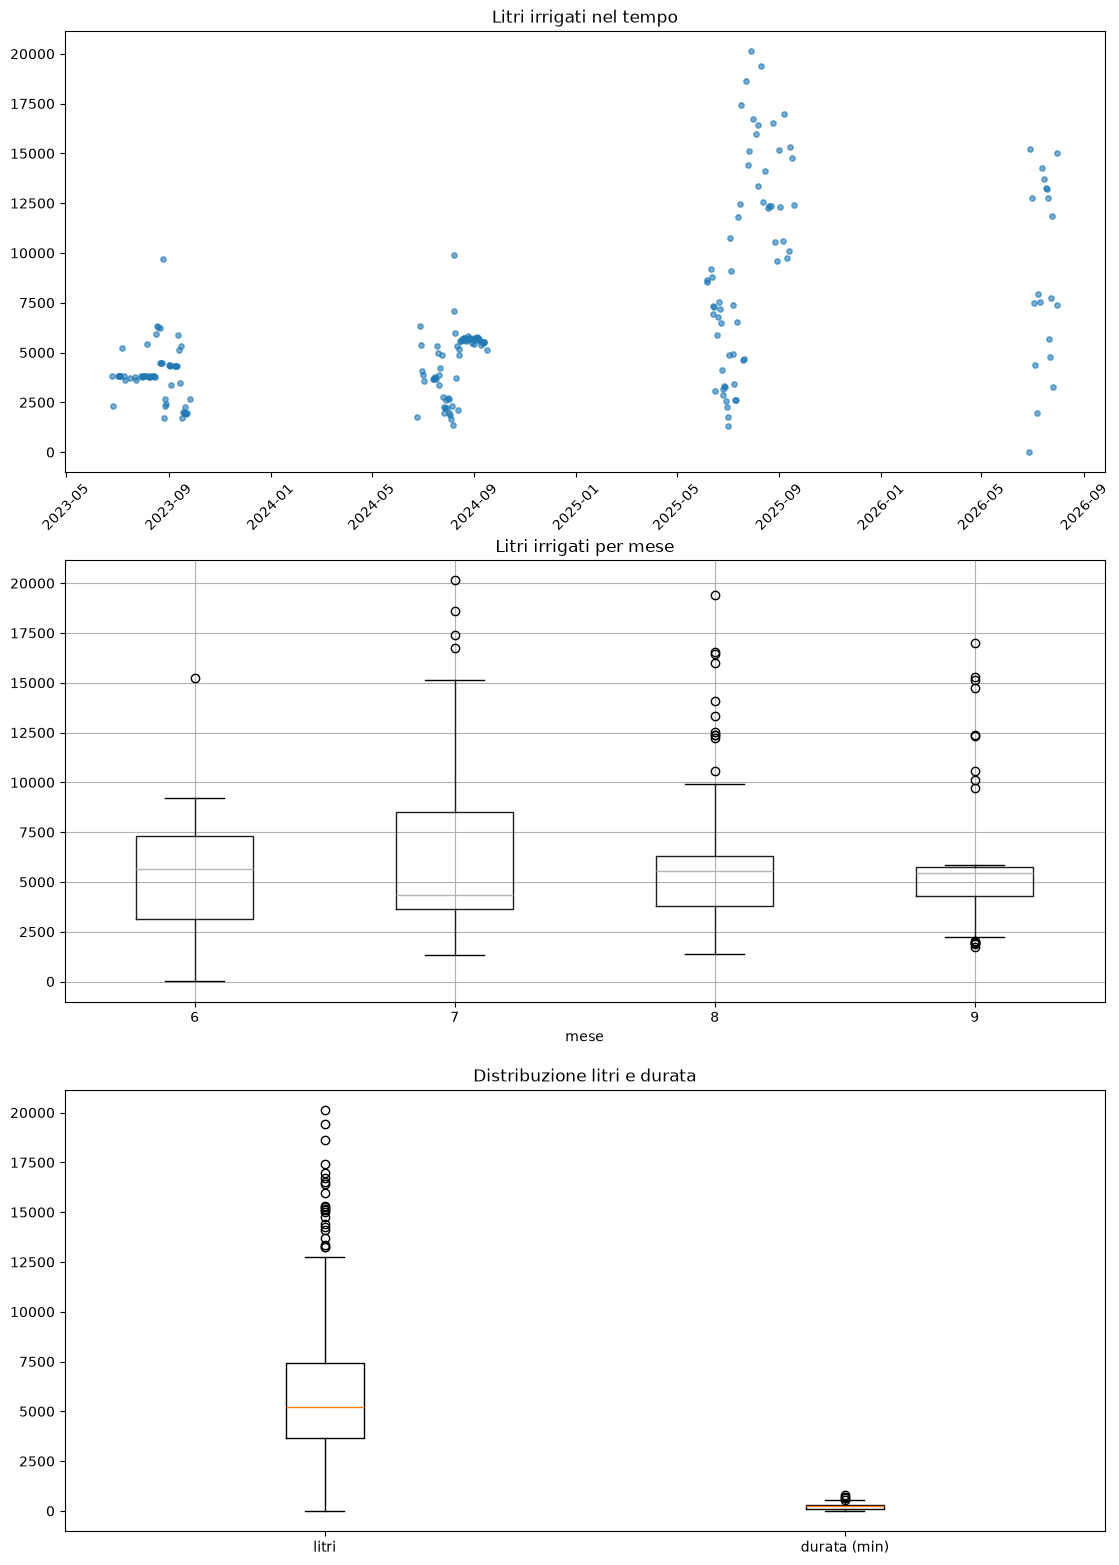

In [41]:
fig, axes = plt.subplots(3, 1, figsize=(13, 20))

# 1. serie temporale: un punto per ogni notte di irrigazione
axes[0].scatter(daily_irrigazione["giorno"], daily_irrigazione["litri_irrigati"], s=15, alpha=0.6)
axes[0].set_title("Litri irrigati nel tempo")
axes[0].tick_params(axis="x", rotation=45)

# 2. boxplot dei litri per MESE, per vedere quali mesi irrigano di piu'
daily_irrigazione["mese"] = daily_irrigazione["giorno"].dt.month
daily_irrigazione.boxplot(column="litri_irrigati", by="mese", ax=axes[1])
axes[1].set_title("Litri irrigati per mese")
plt.suptitle("")

# 3. boxplot semplice delle tre variabili principali (litri, durata, portata)
axes[2].boxplot(
    [daily_irrigazione["litri_irrigati"].dropna(), daily_irrigazione["durata_min"].dropna()],
    tick_labels=["litri", "durata (min)"]
)
axes[2].set_title("Distribuzione litri e durata")




plt.show()

l'irrigazione è concentrata solo giugno-settembre.

guardando il primo grafico, il 2025 ha volumi nettamente più alti del 2023 e del 2024 — nel 2023 il massimo per notte era ~12.000 L, nel 2025 si arriva regolarmente a 15.000-20.000 L. Non è rumore statistico, è un salto di livello sistematico tra stagioni. Possibili spiegazioni: è stata ampliata l'area irrigata, cambiata la valvola/impianto, oppure il 2025 è stata un'annata più siccitosa che ha richiesto più acqua.

# Unione Solem+Dati Meteo

L'obiettivo del progetto è "quando, quanto, per quanto tempo irrigare" — questa è una decisione che si prende una volta al giorno (o meglio, una volta a notte, perchè le irrigazioni vengono fatte di notte come abbiamo visto dal dataset) - quindi avrebbe senso trasformare i dati meteo orari in dati meteo giornalieri perchè se il modello finale deve rispondere a una domanda giornaliera, ha senso che lavori a livello giornaliero. 

Questo ragionamento ha senso anche perchè i dati Solem sono giornalieri e non orari, o meglio ci sono pochi dati al giorno (corrispondenti alle ore notturne di irrigazione), se si dovessero trasformare in dati orari ci sarebbero molti missing values e si dovrebbe procedere a un'imputazione che, coinvolgerebbe troppi dati e quindi l'analisi sarebbe misleading.

Quindi in sintesi abbiamo un dataset orario (una riga per ogni ora) e vogliamo arrivare a uno giornaliero (una riga per ogni giorno). Per farlo si devono prendere tutte le 24 righe di un giorno dai dati meteo e "schiacciarle" in una sola — ma il modo giusto di farlo cambia da colonna a colonna, questo è legato in base a cosa rappresenta fisicamente ogni grandezza nell'arco delle 24 ore.

- **et_mm**: quanta acqua è evaporata in quell'ora. Il totale del giorno è la somma delle 24 ore

- **rainfall_mm**: quanta pioggia è caduta in quell'ora, quindi il totale del giorno è sempre la somma delle 24 ore

- **deg_days_heat**/**deg_days_cool**: gradi-giorno accumulati, si fa sempre la somma per sapere il totale di un giorno.

Queste sono le grandezze che si accumulano, sono grandezze che rappresentano "quanto è successo" in ogni intervallo, e il totale del giorno è la somma di tutti gli intervalli.

Poi ci sono le grandezze che descrivono uno "stato" in un istante, tipo la temperatura, non ha senso sommare sulle 24 ore ma si fa la media: **hum_out**, **bar_hpa**, **thsw_index_c**, **moist_soil_last_1**, **salinity_last_1**, **temp_last_1_c**, **night_cloud_cover**.

**rain_rate_hi_mm** (l'intensità massima di pioggia nell'ora) e **wind_speed_hi_kmh** (la raffica massima), sono dei picchi, qui ci si chiede qual'è stato il valore più estremo della giornata, quindi si prende il massimo.


**bar_trend_cat** non è un numero, è un'etichetta. L'unica operazione sensata è chiedersi "quale etichetta è comparsa più spesso in quelle 24 ore?" — cioè la moda.



In [42]:
df["ts"] = pd.to_datetime(df["ts"]) #df è il dataset meteo 
df["giorno"] = df["ts"].dt.date


In [43]:
agg_rules = {
    "et_mm": "sum", "rainfall_mm": "sum", "deg_days_cool": "sum", "deg_days_heat": "sum",
    "rain_rate_hi_mm": "max", "wind_speed_hi_kmh": "max",
    "hum_out": "mean", "bar_hpa": "mean", "thsw_index_c": "mean",
    "moist_soil_last_1": "mean", "salinity_last_1": "mean", "temp_last_1_c": "mean",
    "night_cloud_cover": "mean",
    "wind_dir_of_hi": lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan,
    "wind_dir_of_prevail": lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan,
    "bar_trend_cat": lambda s: s.mode().iloc[0] if not s.mode().empty else np.nan,
    "water_potential_last": "mean", "direct_reading_last": "mean",
    "watermark_available": "max",
}

In [44]:
daily_meteo = df.groupby(["irrigated", "giorno"]).agg(agg_rules).reset_index()
print(daily_meteo.shape)

(2336, 21)


adesso agganciamo Solem solo della zona irrigata

In [45]:
daily_irrigazione["giorno"] = pd.to_datetime(daily_irrigazione["giorno"]).dt.date

daily_meteo = daily_meteo.merge( #unisc solem e meteo 
    daily_irrigazione[["giorno", "litri_irrigati"]], on="giorno", how="left"
)

# lo zero e' corretto SOLO per la zona irrigata (assenza di irrigazione quel
# giorno); per la zona non irrigata mettiamo esplicitamente 0 per definizione,
# indipendentemente dal merge
daily_meteo["litri_irrigati"] = np.where(
    daily_meteo["irrigated"] == 1, daily_meteo["litri_irrigati"].fillna(0), 0
)

daily_meteo.to_csv("vigneto_daily_finale.csv", index=False)
print(daily_meteo.shape)

(2336, 22)
